In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings("ignore")

In [15]:
#load public transport patronage csv file
df = pd.read_csv(r'avg_patronage.csv', dtype='string', na_values=["", "NA", "N/A", "null", "NULL", "NaN"], keep_default_na=True, low_memory=False )
df.shape

(4300, 7)

In [16]:
#data exploration after enforcing and adding new column
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4300 entries, 0 to 4299
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Year         4300 non-null   string
 1   Month        4300 non-null   string
 2   Month_name   4300 non-null   string
 3   Day_of_week  4300 non-null   string
 4   Day_type     4300 non-null   string
 5   Mode         4300 non-null   string
 6   Pax_daily    4300 non-null   string
dtypes: string(7)
memory usage: 235.3 KB
None
   Year Month Month_name Day_of_week                Day_type           Mode  \
0  2018     1        Jan      Friday  School Holiday Weekday       MetroBus   
1  2018     1        Jan      Friday  School Holiday Weekday     MetroTrain   
2  2018     1        Jan      Friday  School Holiday Weekday    RegionalBus   
3  2018     1        Jan      Friday  School Holiday Weekday  RegionalTrain   
4  2018     1        Jan      Friday  School Holiday Weekday           Tram   

  Pa

In [17]:
#enforce year and month column to int datatype
df['Year'] = df['Year'].astype(int)
df['Month'] = df['Month'].astype(int)
#enforce day of week, day type, mode to category data type
df['Day_of_week'] = df['Day_of_week'].astype('category')
df['Day_type'] = df['Day_type'].astype('category')
df['Mode'] = df['Mode'].astype('category')
#create new column showing first day in month
df['MonthStart'] = pd.to_datetime(
    df['Year'].astype(str) + '-' + df['Month'].astype('str') + '-01'
)

In [18]:
#check exact duplicaes
print(df.duplicated().sum())

#check null
print(df.isna().sum())
print(df['Pax_daily'].isna().sum())

#check anomalies
print(df['Pax_daily'].describe())


#clean labels
cols = ['Day_of_week', 'Day_type', 'Mode']
for col in cols:
    df[col] = df[col].str.strip().str.title()

0
Year           0
Month          0
Month_name     0
Day_of_week    0
Day_type       0
Mode           0
Pax_daily      0
MonthStart     0
dtype: int64
0
count      4300
unique     3181
top       62050
freq          7
Name: Pax_daily, dtype: object


In [5]:
#verify after cleaning
print(df.isna().sum())
print(df.duplicated().sum())
print(df['Mode'].unique())

Year           0
Month          0
Month_name     0
Day_of_week    0
Day_type       0
Mode           0
Pax_daily      0
MonthStart     0
dtype: int64
0
['Metrobus' 'Metrotrain' 'Regionalbus' 'Regionaltrain' 'Tram']


In [19]:
#Engineering feature
#Period
df['Period'] = pd.cut(
    df['Year'],
    bins=[0, 2019, 2021, float('inf')],
    labels=['Pre-2020', '2020-2021', 'Post-2021']
)
print(df['Period'].head())

#is weekday(1) or not(0)
df['Is_Weekday'] = df['Day_of_week'].isin(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
).astype(int)
print(df['Is_Weekday'].head(20))

#rolling mean
df = df.sort_values('MonthStart')

df['Rolling_3M'] = (
    df.groupby(['Mode', 'Day_type'])['Pax_daily']
      .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)

0    Pre-2020
1    Pre-2020
2    Pre-2020
3    Pre-2020
4    Pre-2020
Name: Period, dtype: category
Categories (3, object): ['Pre-2020' < '2020-2021' < 'Post-2021']
0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    0
16    0
17    0
18    0
19    0
Name: Is_Weekday, dtype: int64


In [7]:
df.to_csv('patronage_cleaned.csv', index = False)

In [20]:
# Encode categorical columns
le = LabelEncoder()

cat_cols = ["Month_name", "Day_of_week", "Day_type", "Mode", "Period"]
for col in cat_cols:
    if col in df.columns:
        df[col + "_enc"] = le.fit_transform(df[col].astype(str))

# Convert Is_Weekday to int if boolean
if "Is_Weekday" in df.columns:
    df["Is_Weekday"] = df["Is_Weekday"].map({True: 1, False: 0, "TRUE": 1, "FALSE": 0})

# Define features and target
feature_cols = [
    "Year", "Month",
    "Month_name_enc", "Day_of_week_enc", "Day_type_enc",
    "Mode_enc", "Period_enc",
    "Is_Weekday",
    "Rolling_3M"
]

# Only keep features that actually exist in df
feature_cols = [f for f in feature_cols if f in df.columns]

target = "Pax_daily"

df_model = df[feature_cols + [target]].dropna()

X = df_model[feature_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
y = pd.to_numeric(df_model[target], errors="coerce").fillna(0)

# Debug: confirm all numeric
print("\nX dtypes after conversion:")
print(X.dtypes)
print(f"\nFeatures used: {feature_cols}")
print(f"Dataset size after dropna: {len(df_model)}")


X dtypes after conversion:
Year                 int64
Month                int64
Month_name_enc       int64
Day_of_week_enc      int64
Day_type_enc         int64
Mode_enc             int64
Period_enc           int64
Is_Weekday           int64
Rolling_3M         float64
dtype: object

Features used: ['Year', 'Month', 'Month_name_enc', 'Day_of_week_enc', 'Day_type_enc', 'Mode_enc', 'Period_enc', 'Is_Weekday', 'Rolling_3M']
Dataset size after dropna: 4300


In [21]:
#desciptive analysis
df['Pax_daily'] = pd.to_numeric(df['Pax_daily'], errors='coerce')
df.dropna()

df.groupby(['Mode','Day_type','Day_of_week','Period'])['Pax_daily'].agg(['mean','median']).reset_index()



,Mode,Day_type,Day_of_week,Period,mean,median
0,Metrobus,Normal Weekday,Friday,Pre-2020,429502.272727,437150.0
1,Metrobus,Normal Weekday,Friday,2020-2021,205858.333333,196275.0
2,Metrobus,Normal Weekday,Friday,Post-2021,355588.636364,364950.0
3,Metrobus,Normal Weekday,Monday,Pre-2020,426526.086957,435250.0
4,Metrobus,Normal Weekday,Monday,2020-2021,187572.727273,171650.0
...,...,...,...,...,...,...
310,Tram,Weekend,Tuesday,2020-2021,<NA>,<NA>
311,Tram,Weekend,Tuesday,Post-2021,<NA>,<NA>
312,Tram,Weekend,Wednesday,Pre-2020,<NA>,<NA>
313,Tram,Weekend,Wednesday,2020-2021,<NA>,<NA>


Mode   Metrobus  Metrotrain  Regionalbus  Regionaltrain      Tram
Month                                                            
1      19165350    32194900      1672250        2811950  29783600
2      17606600    28038900      1736350        2311800  25110000
3      19318800    31503350      1837350        2629500  27391500
4      28350500    47071100      2614100        3898450  41448050
5      15935850    26435900      1540300        2270150  22190000
6      18400750    29140700      1860400        2656400  24394250
7      26347400    43144800      2606250        3961550  36510650
8      15187600    24440150      1514250        2086950  20585300
9      24595950    40541550      2387700        3629550  32938850
10     21849350    35673350      2127150        3127000  30172700
11     16648650    25670100      1591500        2237600  22526950
12     19091450    30144000      1800600        2721350  27969600


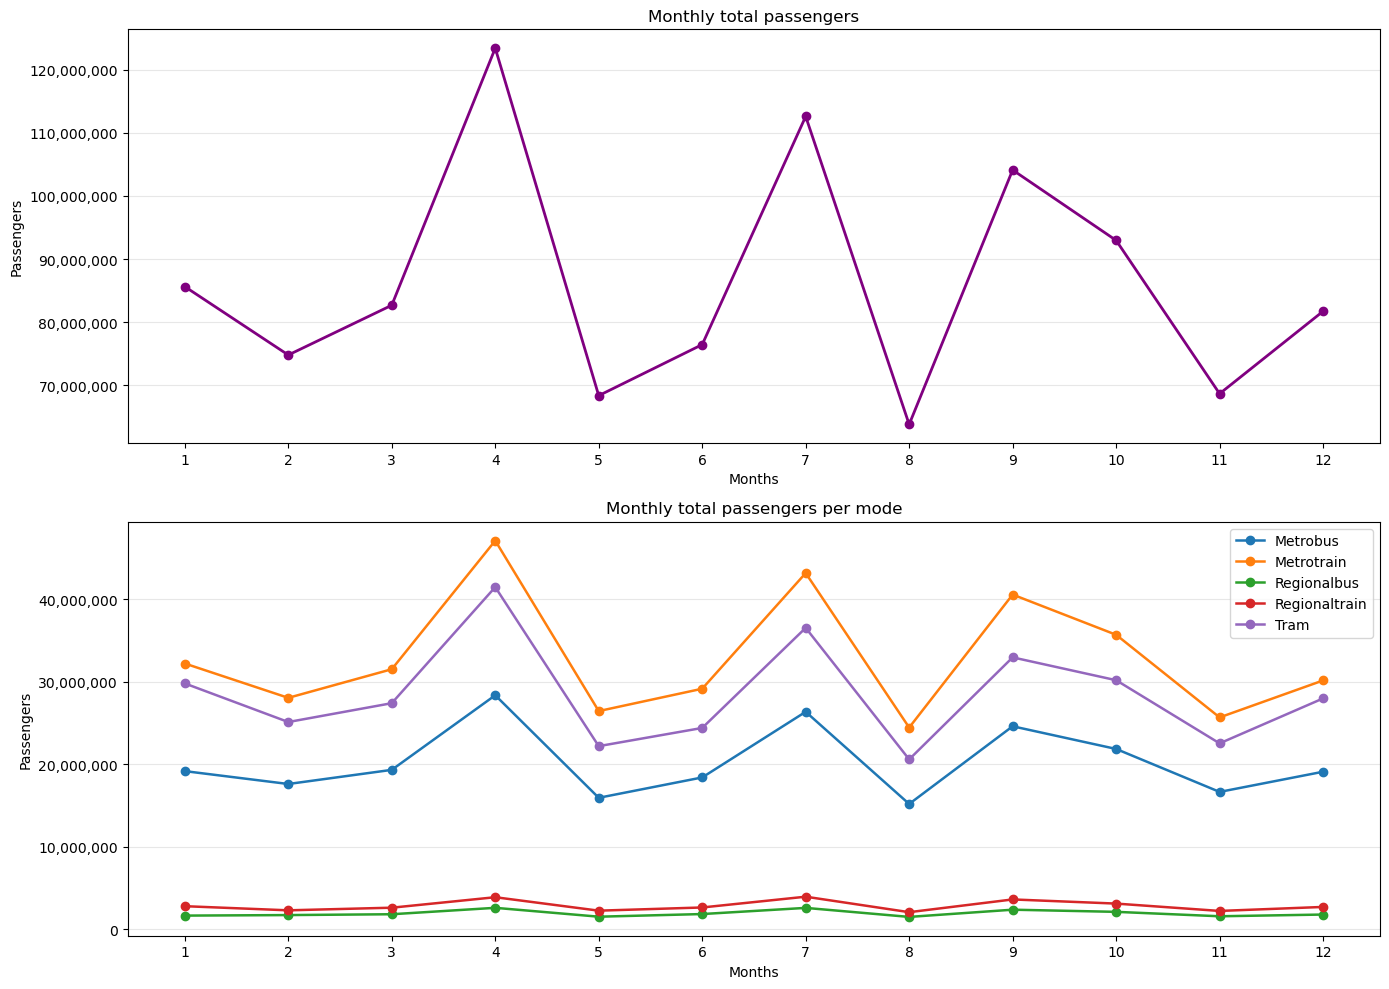

In [23]:
#A. Descriptive analytics(LO1)

summary_mode = (
    df.groupby("Mode", observed=True)["Pax_daily"]
    .agg(["mean", "median"])
    .round(0)
    .reset_index()
)
 
summary_day_type = (
    df.groupby("Day_type", observed=True)["Pax_daily"]
    .agg(["mean", "median"])
    .round(0)
    .reset_index()
)

summary_week_day = (
    df.groupby("Day_of_week", observed=True)["Pax_daily"]
    .agg(["mean", "median"])
    .round(0)
    .reset_index()
)

period_order = ["Pre-2020", "2020-2021", "Post-2021"]
summary_period = (
    df.groupby("Period", observed=True)["Pax_daily"]
    .agg(["mean", "median"])
    .round(0)
    .reindex(period_order)
    .reset_index()
)

monthly_passengers = df.groupby('Month')['Pax_daily'].sum()
monthly_pax_mode = df.groupby(['Month','Mode'])['Pax_daily'].sum().unstack()

print(monthly_pax_mode)


#Summary tables: mean/median Pax_daily ;by Mode, Day_type, Day_of_week, and Period.
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
axes[0].plot(monthly_passengers.index, monthly_passengers.values, color="purple", linewidth=2, marker="o")
axes[0].set_title("Monthly total passengers")
axes[0].set_xlabel("Months")
axes[0].set_ylabel("Passengers")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_xticks(range(1, 13))

#Trend lines: time‑series of monthly; Pax_daily (overall and split by Mode).
for mode in monthly_pax_mode.columns:
    axes[1].plot(monthly_pax_mode.index, monthly_pax_mode[mode], label=mode, linewidth=1.8, marker="o")
axes[1].set_title("Monthly total passengers per mode")
axes[1].set_xlabel("Months")
axes[1].set_ylabel("Passengers")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()



## B. Machine learning (LO2)

In [ ]:
#prepare data for the models
# Text columns (Mode, Day_type, Period) become 0/1 columns, one per category (one-hot encoding)
ml = pd.get_dummies(df[["Year", "Month", "Mode", "Day_type", "Period", "Pax_daily"]],
                    columns=["Mode", "Day_type", "Period"], dtype=int)
features = ml.drop(columns="Pax_daily").columns.tolist()

# Time-based split: learn from the past (2018-2023), test on the future (2024-2025)
train = ml[ml["Year"] <= 2023]
test  = ml[ml["Year"] >= 2024]
X_train, X_test = train[features], test[features]

print("Features:", features)
print(f"Train rows: {len(train)} | Test rows: {len(test)}")

In [ ]:
#1. LINEAR REGRESSION — predict the number of daily passengers
y_train_reg = train["Pax_daily"]
y_test_reg  = test["Pax_daily"]

lin = LinearRegression()
lin.fit(X_train, y_train_reg)          # learn one weight per feature
reg_pred = lin.predict(X_test)         # predict passengers for 2024-2025

print("── Linear Regression ──")
print(f"MAE : {mean_absolute_error(y_test_reg, reg_pred):,.0f} passengers")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, reg_pred)):,.0f} passengers")
print(f"R²  : {r2_score(y_test_reg, reg_pred):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: actual vs predicted — perfect predictions would sit on the dashed line
axes[0].scatter(y_test_reg, reg_pred, s=12, alpha=0.5, color="#3266ad")
max_val = max(y_test_reg.max(), reg_pred.max())
axes[0].plot([0, max_val], [0, max_val], "--", color="#D85A30", label="Perfect prediction")
axes[0].set_title("Linear Regression — Actual vs Predicted (2024-2025)")
axes[0].set_xlabel("Actual Pax_daily")
axes[0].set_ylabel("Predicted Pax_daily")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: coefficients — how many passengers each feature adds (+) or removes (-)
coefs = pd.Series(lin.coef_, index=features).sort_values()
axes[1].barh(coefs.index, coefs.values, color=["#D85A30" if v < 0 else "#1D9E75" for v in coefs.values])
axes[1].set_title("What each feature adds to daily passengers")
axes[1].set_xlabel("Change in Pax_daily")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#2. CLASSIFICATION — is it a busy day for that mode?
# Busy (1) = more passengers than that mode's usual (median) level in the training years, else Quiet (0)
median_by_mode = df.loc[train.index].groupby("Mode", observed=True)["Pax_daily"].median()
busy = (df["Pax_daily"] > df["Mode"].map(median_by_mode).astype(float)).astype(int)
y_train_clf = busy[train.index]
y_test_clf  = busy[test.index]

tree = DecisionTreeClassifier(max_depth=3, random_state=42)   # max 3 questions deep, easy to read
tree.fit(X_train, y_train_clf)
clf_pred = tree.predict(X_test)

print("── Decision Tree Classifier ──")
print(f"Accuracy: {accuracy_score(y_test_clf, clf_pred):.3f}\n")
print(classification_report(y_test_clf, clf_pred, target_names=["Quiet", "Busy"]))

fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 2.5]})

# Left: confusion matrix — diagonal = correct, off-diagonal = mistakes
ConfusionMatrixDisplay.from_predictions(y_test_clf, clf_pred, display_labels=["Quiet", "Busy"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (2024-2025)")

# Right: the tree itself — the yes/no questions the model asks
plot_tree(tree, feature_names=features, class_names=["Quiet", "Busy"],
          filled=True, rounded=True, fontsize=9, ax=axes[1])
axes[1].set_title("Decision Tree — how the model decides")

plt.tight_layout()
plt.show()